# Jev results: how the Enron classifications were produced

This EDA reads the saved [Jev predictions](../data/jev_test_predictions.csv) and
held-out [test labels](../data/enron_labeled_curated_test.csv). It makes **no API
calls**. Jev is a zero-shot decision model; no new weights were trained.

Each email was sent as `state.email` with a fixed yes/no question. The API
returned a probability, and the classifier assigned class 1 when it was at
least 0.5. The notebook verifies the source rows, email hashes, labels, and
scoring rule before describing performance. See the [classifier
code](../scripts/jev_openrouter.py) and [OpenRouter Decisions
API](https://openrouter.ai/docs/api/api-reference/alphadecisions/submit-a-decisions-questions-and-answers-request).


In [1]:
import csv
from collections import Counter
import hashlib
import html
import json
import math
from pathlib import Path
import re
import statistics
import sys
from IPython.display import HTML, SVG, display

REPO = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'data' / 'jev_test_predictions.csv').exists()), None)
if REPO is None:
    raise FileNotFoundError('Start Jupyter from GTPracticum or a child folder')
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))
from scripts.jev_openrouter import API_URL, MODEL, MAX_EMAIL_CHARS, QUESTION, config_hash

with (REPO / 'data' / 'enron_labeled_curated_test.csv').open(newline='', encoding='utf-8-sig') as f:
    source = list(csv.DictReader(f))
with (REPO / 'data' / 'jev_test_predictions.csv').open(newline='', encoding='utf-8') as f:
    saved = list(csv.DictReader(f))
assert len(source) == len(saved) == 559
assert len({int(r['source_row']) for r in saved}) == len(saved), 'Duplicate prediction row'
expected_config = config_hash(MODEL, MAX_EMAIL_CHARS)
rows = []
for result in sorted(saved, key=lambda r: int(r['source_row'])):
    row_id = int(result['source_row'])
    original = source[row_id]
    assert hashlib.sha256(original['email'].encode()).hexdigest() == result['email_sha256'], row_id
    assert int(original['label']) == int(result['label']), row_id
    assert result['config_sha256'] == expected_config, row_id
    probability = float(result['probability'])
    prediction = int(result['prediction'])
    assert 0 <= probability <= 1 and prediction == int(probability >= 0.5), row_id
    label = int(original['label'])
    rows.append({
        'source_row': row_id, 'email': original['email'], 'label': label,
        'prediction': prediction, 'probability': probability,
        'outcome': {(1,1):'TP',(0,0):'TN',(0,1):'FP',(1,0):'FN'}[(label,prediction)],
        'truncated': result['truncated'].lower() == 'true',
        'input_tokens': int(result['input_tokens']), 'cost': float(result['cost']),
        'model': result['model'], 'request_id': result['request_id'],
    })
print('Verified', len(rows), 'unique predictions against email hashes, labels, configuration, and threshold.')
print('Reference labels:', dict(sorted(Counter(r['label'] for r in rows).items())))
print('Resolved model:', ', '.join(sorted({r['model'] for r in rows})))


Verified 559 unique predictions against email hashes, labels, configuration, and threshold.
Reference labels: {0: 486, 1: 73}
Resolved model: typesafe/jev-1.13-20260917


## 1. Trace one prediction

The request contained the email text (up to `MAX_EMAIL_CHARS`) and the fixed
question below. Neither the reference label nor the search phrase was sent.
The response field `answers.relevant.noul` is the probability of class 1.
The predictions CSV saves that number, the resolved model, request ID, usage,
and cost. It does not save the complete API response.


In [2]:
print('Endpoint:', API_URL)
print('Requested model:', MODEL)
print('Character limit:', MAX_EMAIL_CHARS)
print('Question and criteria:')
print(json.dumps(QUESTION, indent=2))
example = min((r for r in rows if r['outcome'] == 'TP'),
              key=lambda r: abs(r['probability'] - 0.5))
preview = re.sub(r'\s+', ' ', example['email'])[:420]
print('\nExample source row:', example['source_row'])
print('Email excerpt:', preview + ('...' if len(example['email']) > 420 else ''))
print('Actual email characters sent:', min(len(example['email']), MAX_EMAIL_CHARS))
print('Returned noul probability:', example['probability'])
print('Threshold calculation:', f"{example['probability']:.2f} >= 0.50 -> {example['prediction']}")
print('Reference label:', example['label'], '| outcome:', example['outcome'])
print('Resolved model:', example['model'], '| request ID:', example['request_id'])


Endpoint: https://openrouter.ai/api/alpha/decisions
Requested model: typesafe/jev-1.13
Character limit: 20000
Question and criteria:
{
  "type": "noul",
  "instructions": "Does this email contain substantive evidence or discussion of Enron accounting irregularities, misleading financial reporting, improper mark-to-market valuation, concealment of losses, or misuse of special purpose entities such as the Raptors? Judge the email content, not the sender or search phrase.",
  "criteria": {
    "true": "The email substantively discusses or documents one of those Enron accounting concerns, including a relevant news report, allegation, internal concern, or description of the practice.",
    "false": "The email is unrelated, or only mentions finance or accounting in a routine way without a substantive Enron irregularity concern."
  }
}

Example source row: 427
Email excerpt: ting indictment of what went on inside Enron, Dorgan, a North Dakota Democrat, said. "Lay and others would do a service

## 2. Reproduce the reported performance

The confusion matrix compares saved predictions with held-out labels.
Precision is `TP / (TP + FP)`, recall is `TP / (TP + FN)`, and F1 is their
harmonic mean. Accuracy is also shown beside the always-negative baseline
because the dataset has many more negative examples.


In [3]:
counts = Counter(r['outcome'] for r in rows)
tp, tn, fp, fn = (counts[k] for k in ('TP', 'TN', 'FP', 'FN'))
precision = tp/(tp+fp)
recall = tp/(tp+fn)
accuracy = (tp+tn)/len(rows)
f1 = 2*precision*recall/(precision+recall)
majority_accuracy = (tn+fp)/len(rows)
metrics = {'rows':len(rows),'TP':tp,'TN':tn,'FP':fp,'FN':fn,
           'accuracy':accuracy,'precision':precision,'recall':recall,'F1':f1}
with (REPO / 'data' / 'jev_evaluation.json').open(encoding='utf-8') as f:
    reported = json.load(f)['metrics']
for name, expected in [('accuracy',accuracy),('precision',precision),('recall',recall),('f1',f1)]:
    assert math.isclose(reported[name], expected), name
print('                       Predicted 0   Predicted 1')
print(f'Actual 0 (negative)       {tn:>4} TN       {fp:>4} FP')
print(f'Actual 1 (positive)       {fn:>4} FN       {tp:>4} TP')
print(f'Accuracy {accuracy:.1%} | Precision {precision:.1%} | Recall {recall:.1%} | F1 {f1:.1%}')
print(f'Always-negative accuracy: {majority_accuracy:.1%}')


                       Predicted 0   Predicted 1
Actual 0 (negative)        462 TN         24 FP
Actual 1 (positive)         22 FN         51 TP
Accuracy 91.8% | Precision 68.0% | Recall 69.9% | F1 68.9%
Always-negative accuracy: 86.9%


## 3. Where the probabilities fall

The panels separate reference labels 0 and 1. Each panel has its own count
scale so the smaller positive class is visible. The dashed line is the 0.5
decision threshold. The chart shows the observed score distribution, not
which words or features the model used internally.


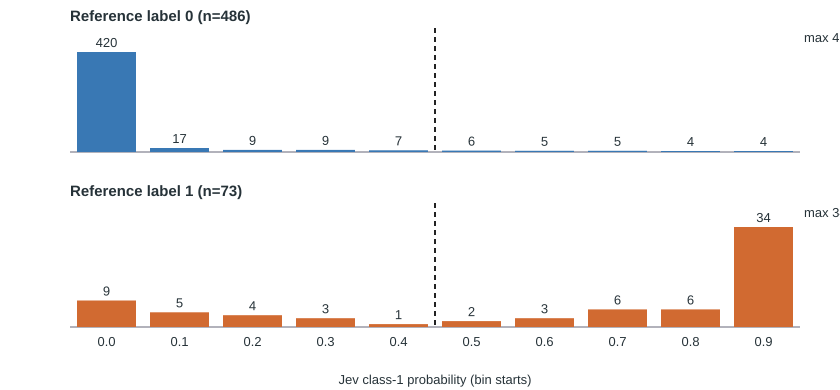

In [4]:
def histogram_svg(data):
    w, h, left, right = 840, 390, 70, 800
    out = [f'<svg xmlns="http://www.w3.org/2000/svg" width="{w}" height="{h}" viewBox="0 0 {w} {h}">',
           '<rect width="100%" height="100%" fill="white"/>',
           '<style>text{font:13px Arial,sans-serif;fill:#263238}.title{font:bold 15px Arial,sans-serif}</style>']
    for panel, label, color, title in [(0,0,'#3978b4','Reference label 0'),
                                        (1,1,'#d16a31','Reference label 1')]:
        top = 28 + panel*175
        baseline = top + 124
        values = [sum(r['label']==label and i/10<=r['probability']<((i+1)/10 if i<9 else 1.001)
                      for r in data) for i in range(10)]
        peak = max(values)
        out.append(f'<text class="title" x="{left}" y="{top-7}">{title} (n={sum(values)})</text>')
        out.append(f'<line x1="{left}" y1="{baseline}" x2="{right}" y2="{baseline}" stroke="#667"/>')
        for i, n in enumerate(values):
            x = left+i*(right-left)/10+7
            bw = (right-left)/10-14
            bh = 100*n/peak
            out.append(f'<rect x="{x:.1f}" y="{baseline-bh:.1f}" width="{bw:.1f}" height="{bh:.1f}" fill="{color}"/>')
            out.append(f'<text x="{x+bw/2:.1f}" y="{baseline-bh-5:.1f}" text-anchor="middle">{n}</text>')
            if panel==1:
                out.append(f'<text x="{x+bw/2:.1f}" y="{baseline+19}" text-anchor="middle">{i/10:.1f}</text>')
        cut = left+(right-left)/2
        out.append(f'<line x1="{cut}" y1="{top}" x2="{cut}" y2="{baseline}" stroke="#222" stroke-width="2" stroke-dasharray="5 4"/>')
        out.append(f'<text x="{right+4}" y="{top+14}">max {peak}</text>')
    out.append('<text x="435" y="384" text-anchor="middle">Jev class-1 probability (bin starts)</text></svg>')
    return ''.join(out)
display(SVG(histogram_svg(rows)))


### Probability check

The table compares mean Jev probability with the observed positive share in
five score bands. Small bands are noisy; these numbers describe this test set
and do not establish calibration for future emails.


In [5]:
print('Probability band   Emails   Mean score   Positive share')
for i in range(5):
    low, high = i/5, (i+1)/5
    band = [r for r in rows if low <= r['probability'] < (high if i<4 else 1.001)]
    mean_score = statistics.mean(r['probability'] for r in band)
    positive_share = statistics.mean(r['label'] for r in band)
    print(f'{low:.1f}–{high:.1f}              {len(band):>3}       {mean_score:>5.1%}          {positive_share:>5.1%}')
brier = statistics.mean((r['probability']-r['label'])**2 for r in rows)
print(f'Brier score (lower is better): {brier:.4f}')


Probability band   Emails   Mean score   Positive share
0.0–0.2              451        2.4%           3.1%
0.2–0.4               25       28.8%          28.0%
0.4–0.6               16       50.6%          18.8%
0.6–0.8               19       69.8%          47.4%
0.8–1.0               48       92.3%          83.3%
Brier score (lower is better): 0.0606


## 4. Threshold sensitivity

The deployed rule was fixed at 0.5. This sweep is descriptive. Selecting a
new threshold on the held-out test set would bias its reported performance;
use a separate validation set if the threshold needs tuning.


threshold 0.3: precision 57.9%, recall 75.3%, F1 65.5%, predicted positive 95
threshold 0.5: precision 68.0%, recall 69.9%, F1 68.9%, predicted positive 75
threshold 0.7: precision 78.0%, recall 63.0%, F1 69.7%, predicted positive 59


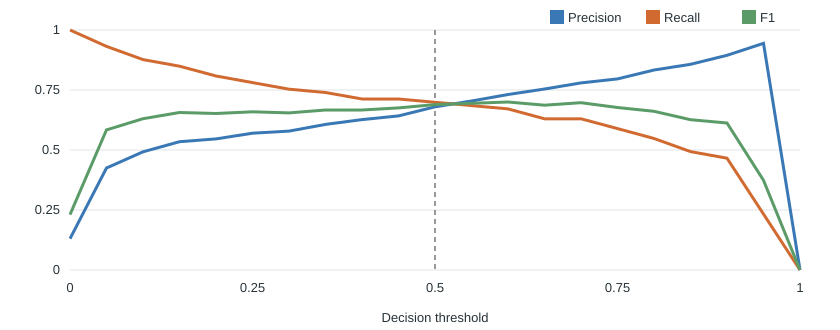

In [6]:
def at_threshold(data, threshold):
    tp = sum(r['label']==1 and r['probability']>=threshold for r in data)
    fp = sum(r['label']==0 and r['probability']>=threshold for r in data)
    fn = sum(r['label']==1 and r['probability']<threshold for r in data)
    p = tp/(tp+fp) if tp+fp else 0
    rec = tp/(tp+fn) if tp+fn else 0
    f = 2*p*rec/(p+rec) if p+rec else 0
    return {'threshold':threshold,'precision':p,'recall':rec,'f1':f,'predicted_positive':tp+fp}
sweep = [at_threshold(rows, i/20) for i in range(21)]
for t in (0.3, 0.5, 0.7):
    x = at_threshold(rows, t)
    print(f"threshold {t:.1f}: precision {x['precision']:.1%}, recall {x['recall']:.1%}, F1 {x['f1']:.1%}, predicted positive {x['predicted_positive']}")

def sweep_svg(points):
    w,h,x0,y0,x1,y1 = 840,330,70,30,800,270
    out = [f'<svg xmlns="http://www.w3.org/2000/svg" width="{w}" height="{h}" viewBox="0 0 {w} {h}">',
           '<rect width="100%" height="100%" fill="white"/>',
           '<style>text{font:13px Arial,sans-serif;fill:#263238}</style>']
    for v in (0,.25,.5,.75,1):
        y = y1-v*(y1-y0)
        x = x0+v*(x1-x0)
        out.append(f'<line x1="{x0}" y1="{y:.1f}" x2="{x1}" y2="{y:.1f}" stroke="#e0e4e8"/>')
        out.append(f'<text x="{x0-10}" y="{y+4:.1f}" text-anchor="end">{v:.2g}</text>')
        out.append(f'<text x="{x:.1f}" y="{y1+22}" text-anchor="middle">{v:.2g}</text>')
    mid = (x0+x1)/2
    out.append(f'<line x1="{mid}" y1="{y0}" x2="{mid}" y2="{y1}" stroke="#333" stroke-dasharray="5 4"/>')
    for key,color in [('precision','#3978b4'),('recall','#d16a31'),('f1','#5a9b68')]:
        coords = ' '.join(f"{x0+p['threshold']*(x1-x0):.1f},{y1-p[key]*(y1-y0):.1f}" for p in points)
        out.append(f'<polyline points="{coords}" fill="none" stroke="{color}" stroke-width="3"/>')
    out.append('<text x="435" y="322" text-anchor="middle">Decision threshold</text>')
    for i,(name,color) in enumerate([('Precision','#3978b4'),('Recall','#d16a31'),('F1','#5a9b68')]):
        out.append(f'<rect x="{550+i*96}" y="10" width="14" height="14" fill="{color}"/>')
        out.append(f'<text x="{568+i*96}" y="22">{name}</text>')
    return ''.join(out)+'</svg>'
display(SVG(sweep_svg(sweep)))


## 5. Review the strongest disagreements

False positives are negative-labeled emails scored at or above 0.5; false
negatives are positive-labeled emails scored below 0.5. These short excerpts
highlight the most confident errors for manual review. They do not establish
why Jev chose those scores, and the reference labels may also deserve review.

The [full review of all 22 false negatives](jev_false_negatives_review.md) separates clear accounting cues, related context, and labels that need checking against the classifier rule.


In [7]:
def error_table(title, examples):
    body = []
    for r in examples:
        excerpt = re.sub(r'\s+', ' ', r['email'])[:260]
        body.append('<tr><td>{}</td><td>{:.2f}</td><td>{}</td></tr>'.format(
            r['source_row'], r['probability'], html.escape(excerpt)))
    table = ('<h3>'+html.escape(title)+'</h3><table style="border-collapse:collapse;max-width:1000px">'
             '<tr><th>Source row</th><th>Jev probability</th><th>Email excerpt</th></tr>'
             +''.join(body)+'</table>')
    display(HTML(table))
false_positives = sorted((r for r in rows if r['outcome']=='FP'), key=lambda r:-r['probability'])
false_negatives = sorted((r for r in rows if r['outcome']=='FN'), key=lambda r:r['probability'])
error_table('Highest-scoring false positives', false_positives[:5])
error_table('Lowest-scoring false negatives', false_negatives[:5])


Source row,Jev probability,Email excerpt
349,0.96,"now as the reason for its woes.=20Enron, established in 1985, grew from a modest natural gas pipeline company= with annual revenue of less than $5-billion to an energy giant with revenu=e pegged at about $200-billion this year.=20To finance this explosive rate"
42,0.93,An unidentified employee sent a letter to Enron Chairman Kenneth Laylast summer that alleged the company would implode in a wave of accountingscandals unless the it changed its accounting practices. The employee alsomet with Lay to provide proof. Two congressm
60,0.93,"A February 6, 2001 Andersen memo detailing a executive meetingwhere the amount of debt kept off Enron's books was discussed hassurfaced. Andersen said the meeting was just a standard annual reviewof Enron. The executives discussed whether Anderson should drop"
17,0.90,"hers."" ? The Senate Health and Education Committee will hold a hearing Thursday focusing on pension laws and 401(k) retirement plans Nicole Maestri is a reporter for CBS.MarketWatch.com in New York. Matt Andrejczak is a reporter for CBS.MarketWatch.com in Wash"
540,0.88,"LONDON -(Dow Jones)- Issues bedeviling the accounting profession for years have finally flashed into the headlines, thanks to Enron and the bursting of the Internet bubble.Unhappily, most are unlikely to be solved anytime soon. Questions of auditor independenc"


Source row,Jev probability,Email excerpt
262,0.01,"financial condition, implement/monitor internal controls, identify and takeaction to reduce significant risks, and provide exemplary CentralAdministration support to operating entities.Ensure that financial statements are prepared on time and in accordancewith"
108,0.02,"Some industry skepticism notwithstanding, this exposure draft seems not tohave stirred up the same sort of hornets' nest as have other recent FASBinitiatives, such as the recent elimination of asset pooling for mergers.All mergers initiated after June 30, 2001"
18,0.03,"Enron spokeswoman Karen Denne said employees' access to the accounts was bl=ocked as part of a previously planned change in the administration of the r=etirement plan and that the measure was in effect from Oct. 26. to Nov. 19.==20Steve Lacey, a 45-year-old em"
254,0.03,-bid & to prevent market manipulation. Note failure of APX to enforce its Rules causes losses both to: (a) ECTRL on its physical sales onto APX from Germany (and Belgium) by virtue of other parties preventing legitimate level of sales by ECTRL by breaching APX
479,0.03,"Subject: Document RetentionTim, Here is the email you should send out with respect to retention ofhard copies of documents.IMPORTANT EPMI POLICY REGARDING HARD COPY DOCUMENTSWHILE LITIGATION IS PENDINGThis policy is in addition to my prior email about the proc"


## 6. Request and data quality

Input token counts and cost come from OpenRouter's saved usage fields. The
predictions CSV stores hashes rather than another copy of the emails. Jev
returns a typed answer and probability, not a rationale or feature
attribution. This EDA shows the observable pipeline and error patterns; it
cannot identify the model's internal reasons for one decision. See TypeSafe's
[System One documentation](https://docs.typesafe.ai/concepts/system-one).


In [8]:
lengths = [len(r['email']) for r in rows]
tokens = [r['input_tokens'] for r in rows]
print('Emails:', len(rows), '| truncated:', sum(r['truncated'] for r in rows))
print('Email characters: median', round(statistics.median(lengths)), '| max', max(lengths))
print('Input tokens: total', sum(tokens), '| median', round(statistics.median(tokens)), '| max', max(tokens))
print('OpenRouter cost: ${:.4f}'.format(sum(r['cost'] for r in rows)))
print('Missing request IDs:', sum(not r['request_id'] for r in rows))
print('Resolved model versions:', dict(Counter(r['model'] for r in rows)))


Emails: 559 | truncated: 0
Email characters: median 1407 | max 2970
Input tokens: total 441301 | median 758 | max 1629
OpenRouter cost: $0.0185
Missing request IDs: 0
Resolved model versions: {'typesafe/jev-1.13-20260917': 559}
